# PSF-aware ResNet redesign — diagnostic review

This notebook reviews the matched ten-epoch redesign experiments, separately from the paper figures. It reads saved results only: no training, model inference, or test-set access.

Two branches add input PSF/noise/mask information, with or without a bounded inverse-filter feature. Compare both with the original ResNet and the matched extra-training control. Check reconstruction, structure, shapes and measurement success together; sharper-looking images alone are insufficient.

Protocol: `paper/psf_redesign_protocol.md`. The earlier synthetic shear pilot is in `paper/shear_response_pilot.md` and remains a separate experiment.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'HANDOFF_GPU.md').exists())
OUT = ROOT / 'runs/psf-redesign-comparison-v01'
ready = (OUT / 'status.json').exists() and json.loads((OUT / 'status.json').read_text()).get('complete', False)
for branch in ['conditioned', 'deconv']:
    run = ROOT / f'runs/psf-redesign-{branch}-v01'
    progress = json.loads((run / 'progress.json').read_text()) if (run / 'progress.json').exists() else {}
    live = json.loads((run / 'live.json').read_text()) if (run / 'live.json').exists() else {}
    status = json.loads((run / 'status.json').read_text()) if (run / 'status.json').exists() else {}
    print(branch, 'complete:', status.get('complete', False), 'completed epoch:', progress.get('epoch'), 'latest update:', max(live.get('updates', 0), progress.get('updates', 0)))
if ready:
    report = json.loads((OUT / 'comparison.json').read_text())
    display(Markdown((OUT / 'report.md').read_text().split('![RMSE]')[0]))
else:
    print('The complete comparison will appear automatically after both runs finish. Rerun this notebook to refresh.')

conditioned complete: True completed epoch: 10 latest update: 22270
deconv complete: True completed epoch: 10 latest update: 22270


# PSF-aware ResNet comparison

All ten epochs completed. Selection uses source MAE with the unchanged parent eligible. Validation only.

| Model | Epoch | Source RMSE | Outside RMSE | Fixed shape RMSE | Adaptive shape RMSE |
| --- | ---: | ---: | ---: | ---: | ---: |
| legacy | 0 | 0.0601735 | 0.0139575 | 0.1899289 | 0.2389572 |
| control_best | 5 | 0.0594465 | 0.0139444 | 0.1898303 | 0.2379333 |
| control_last | 10 | 0.0600835 | 0.0139518 | 0.1896360 | 0.2381988 |
| conditioned_best | 5 | 0.0593742 | 0.0139442 | 0.1879635 | 0.2381441 |
| conditioned_last | 10 | 0.0600270 | 0.0139375 | 0.1885838 | 0.2388238 |
| deconv_best | 5 | 0.0593513 | 0.0139416 | 0.1883541 | 0.2387924 |
| deconv_last | 10 | 0.0599163 | 0.0139363 | 0.1888615 | 0.2392298 |

Compare against both original and extra-training control; inspect paired intervals and failure counts in comparison.json.



Both runs completed all ten epochs and selected epoch 5. The redesign adds only **0.12–0.16% source-RMSE reduction over the matched extra-training control**, with paired intervals including zero. PSF/noise improves fixed-weight shapes, but neither candidate clearly improves adaptive shapes. Fixed images remain very similar. The recommendation is to retain the original paper model; see `paper/psf_redesign_results.md` for the full interpretation and limitations.

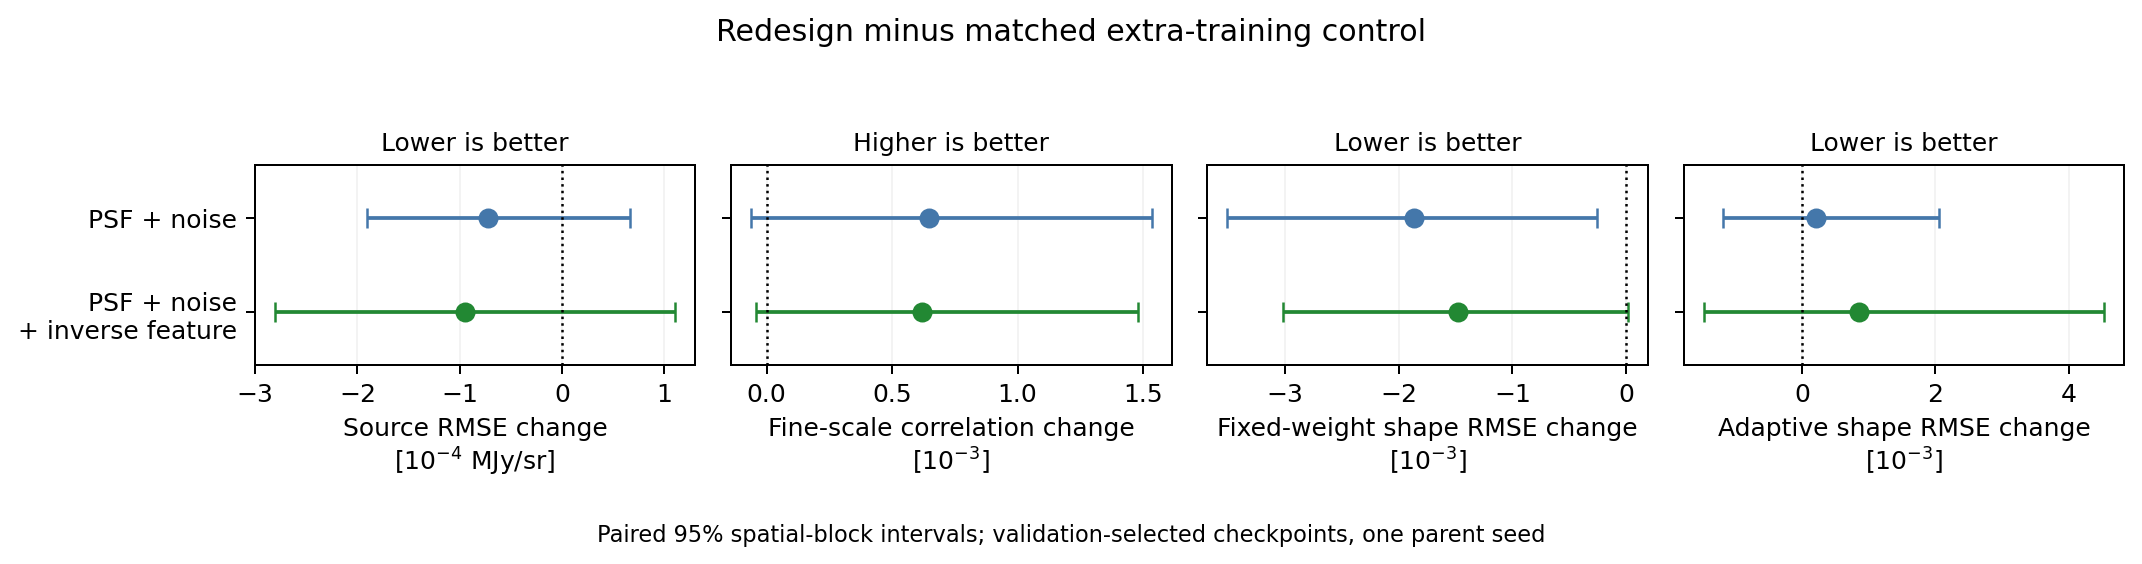

In [2]:
if ready:
    paired_plot = ROOT / 'paper/diagnostics/psf_redesign_paired_v01.png'
    if paired_plot.exists():
        display(Image(filename=str(paired_plot)))

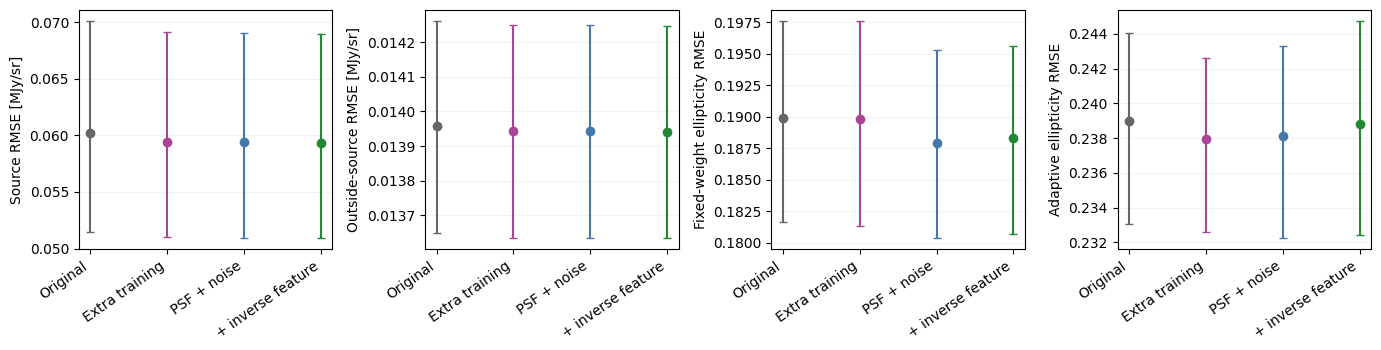

fixed common successful objects: 1627 / 2118
Individual success counts: {'legacy': 1786, 'control_best': 1785, 'conditioned_best': 1796, 'deconv_best': 1793}
adaptive common successful objects: 1700 / 2118
Individual success counts: {'legacy': 1742, 'control_best': 1740, 'conditioned_best': 1749, 'deconv_best': 1747}


In [3]:
# Editable compact comparison of selected checkpoints. Intervals are paired spatial-block bootstraps.
if ready:
    names = ['legacy', 'control_best', 'conditioned_best', 'deconv_best']
    labels = ['Original', 'Extra training', 'PSF + noise', '+ inverse feature']
    colors = ['0.4', '#aa4499', '#4477aa', '#228833']
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
    panels = [(report['errors'], 'source_rmse', 'Source RMSE [MJy/sr]'),
              (report['errors'], 'outside_rmse', 'Outside-source RMSE [MJy/sr]'),
              (report['shapes']['fixed']['methods'], 'component_rmse', 'Fixed-weight ellipticity RMSE'),
              (report['shapes']['adaptive']['methods'], 'component_rmse', 'Adaptive ellipticity RMSE')]
    for ax, (table, key, ylabel) in zip(axes, panels):
        for j, (name, color) in enumerate(zip(names, colors)):
            value = table[name][key]
            ax.errorbar(j, value['mean'], yerr=np.abs(np.asarray(value['ci95']) - value['mean'])[:, None], fmt='o', color=color, capsize=3)
        ax.set_xticks(range(4), labels, rotation=35, ha='right')
        ax.set_ylabel(ylabel)
        ax.grid(axis='y', alpha=.15)
    fig.tight_layout()
    plt.show()
    for kind in ['fixed', 'adaptive']:
        table = report['shapes'][kind]
        print(kind, 'common successful objects:', table['common_successes'], '/', table['objects'])
        print('Individual success counts:', {name: table['success_counts'][name] for name in names})

### Sharpness structure

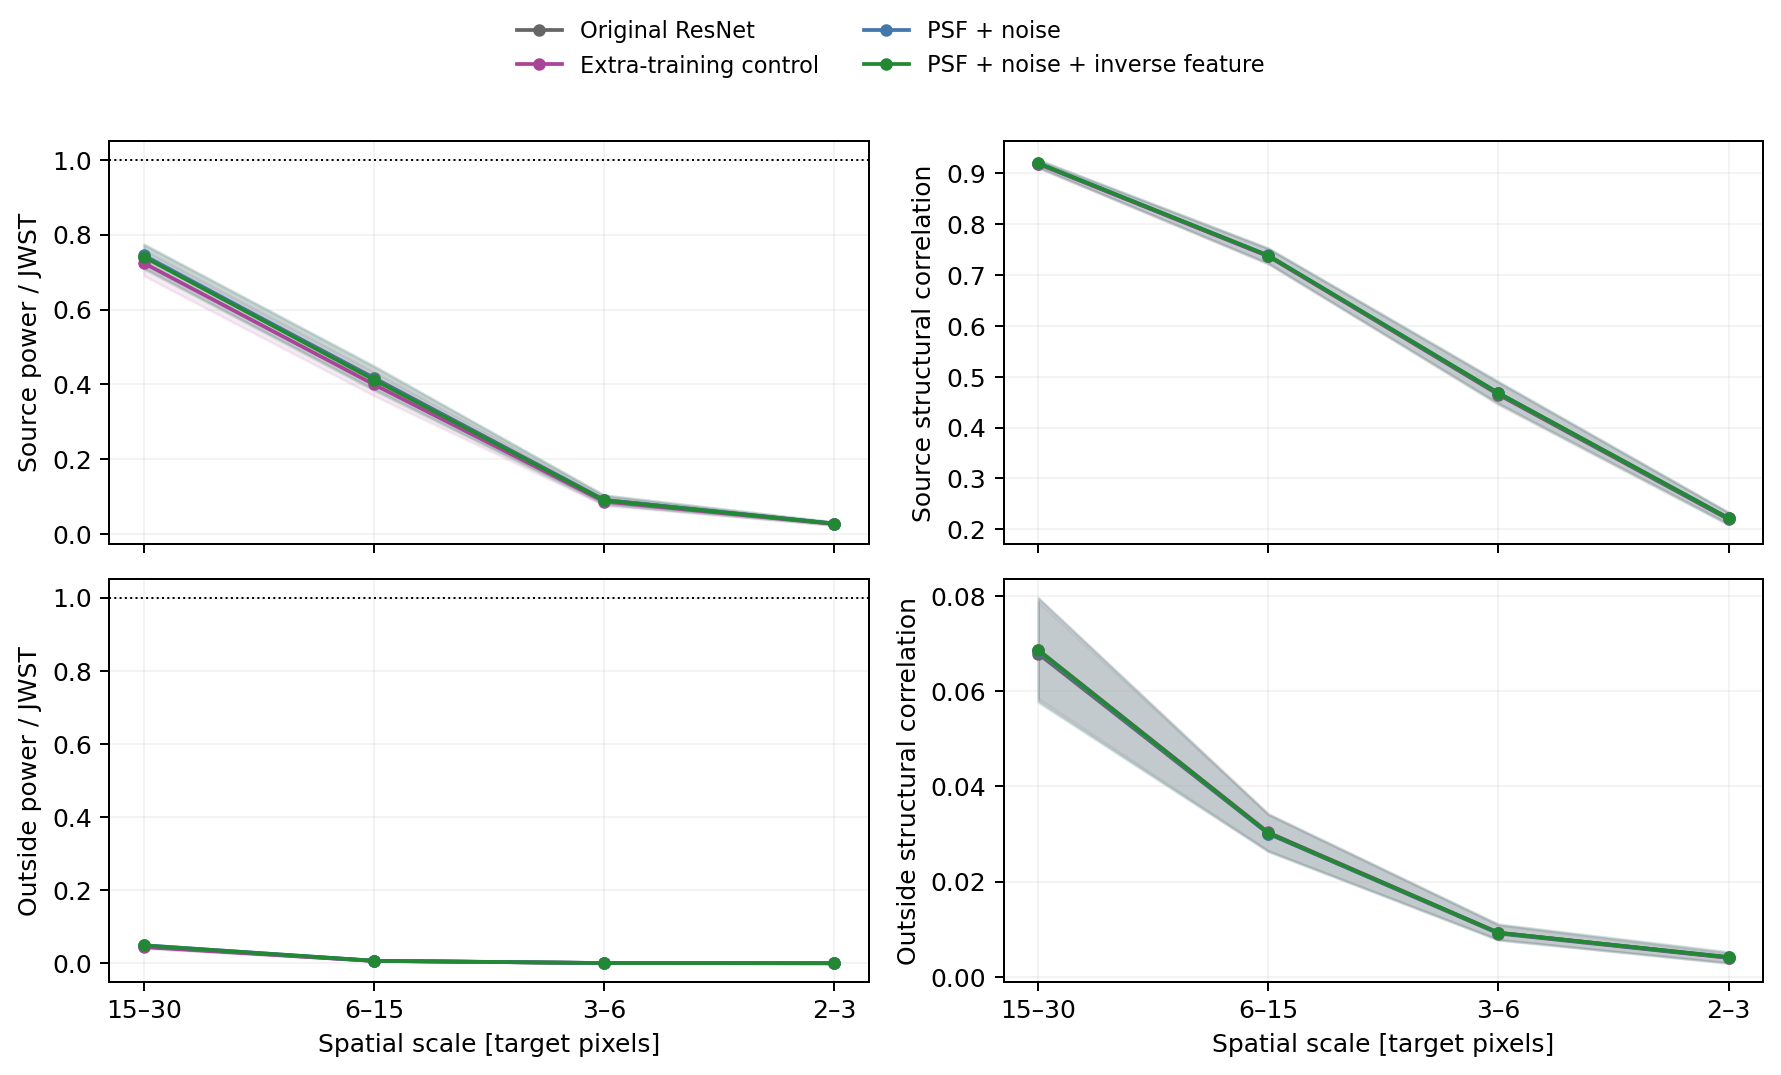

### Learning curves

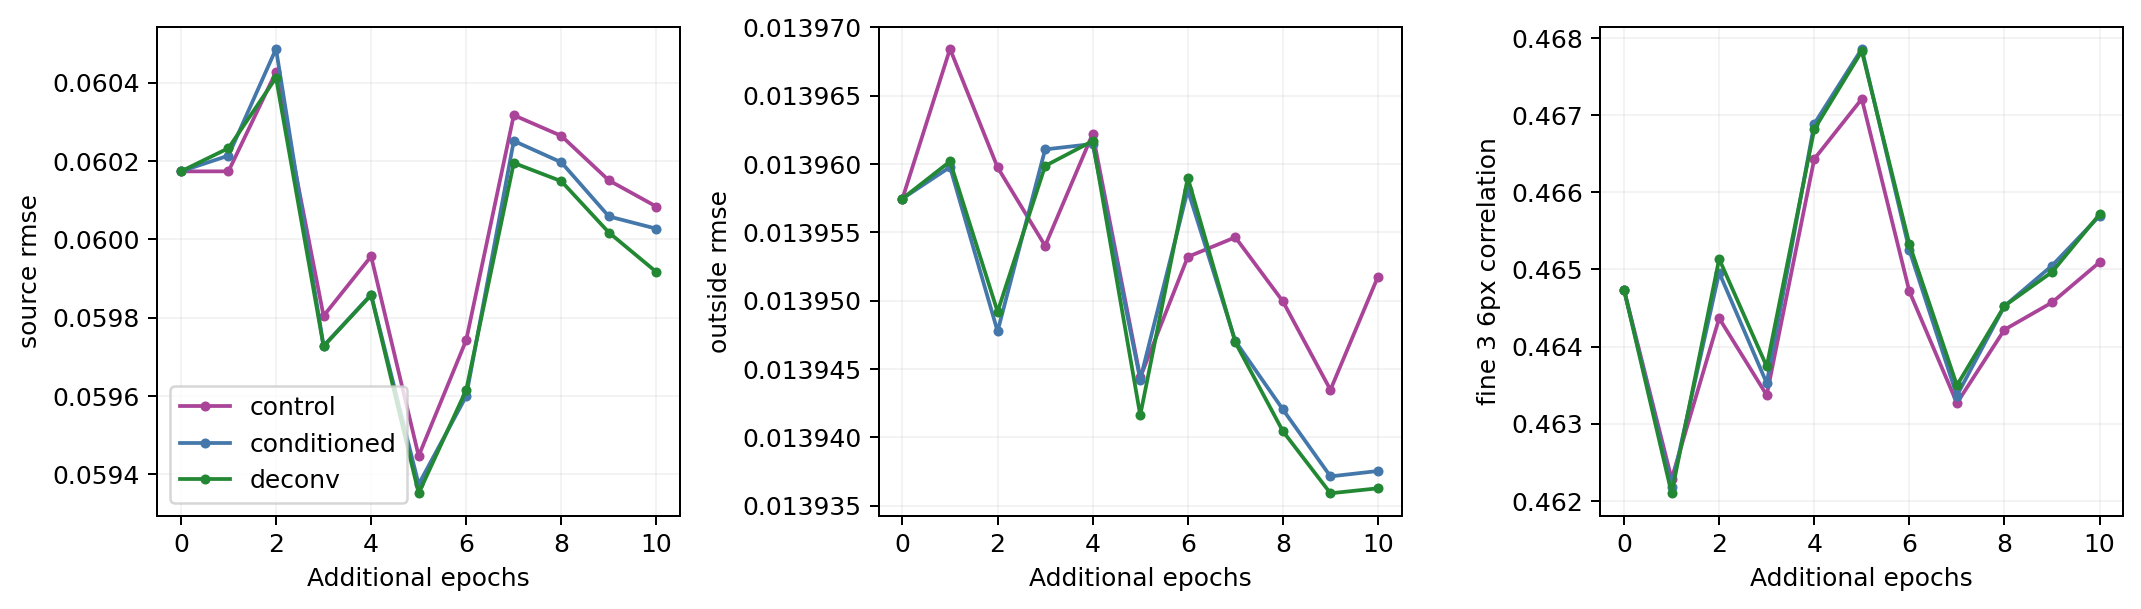

### Fixed images

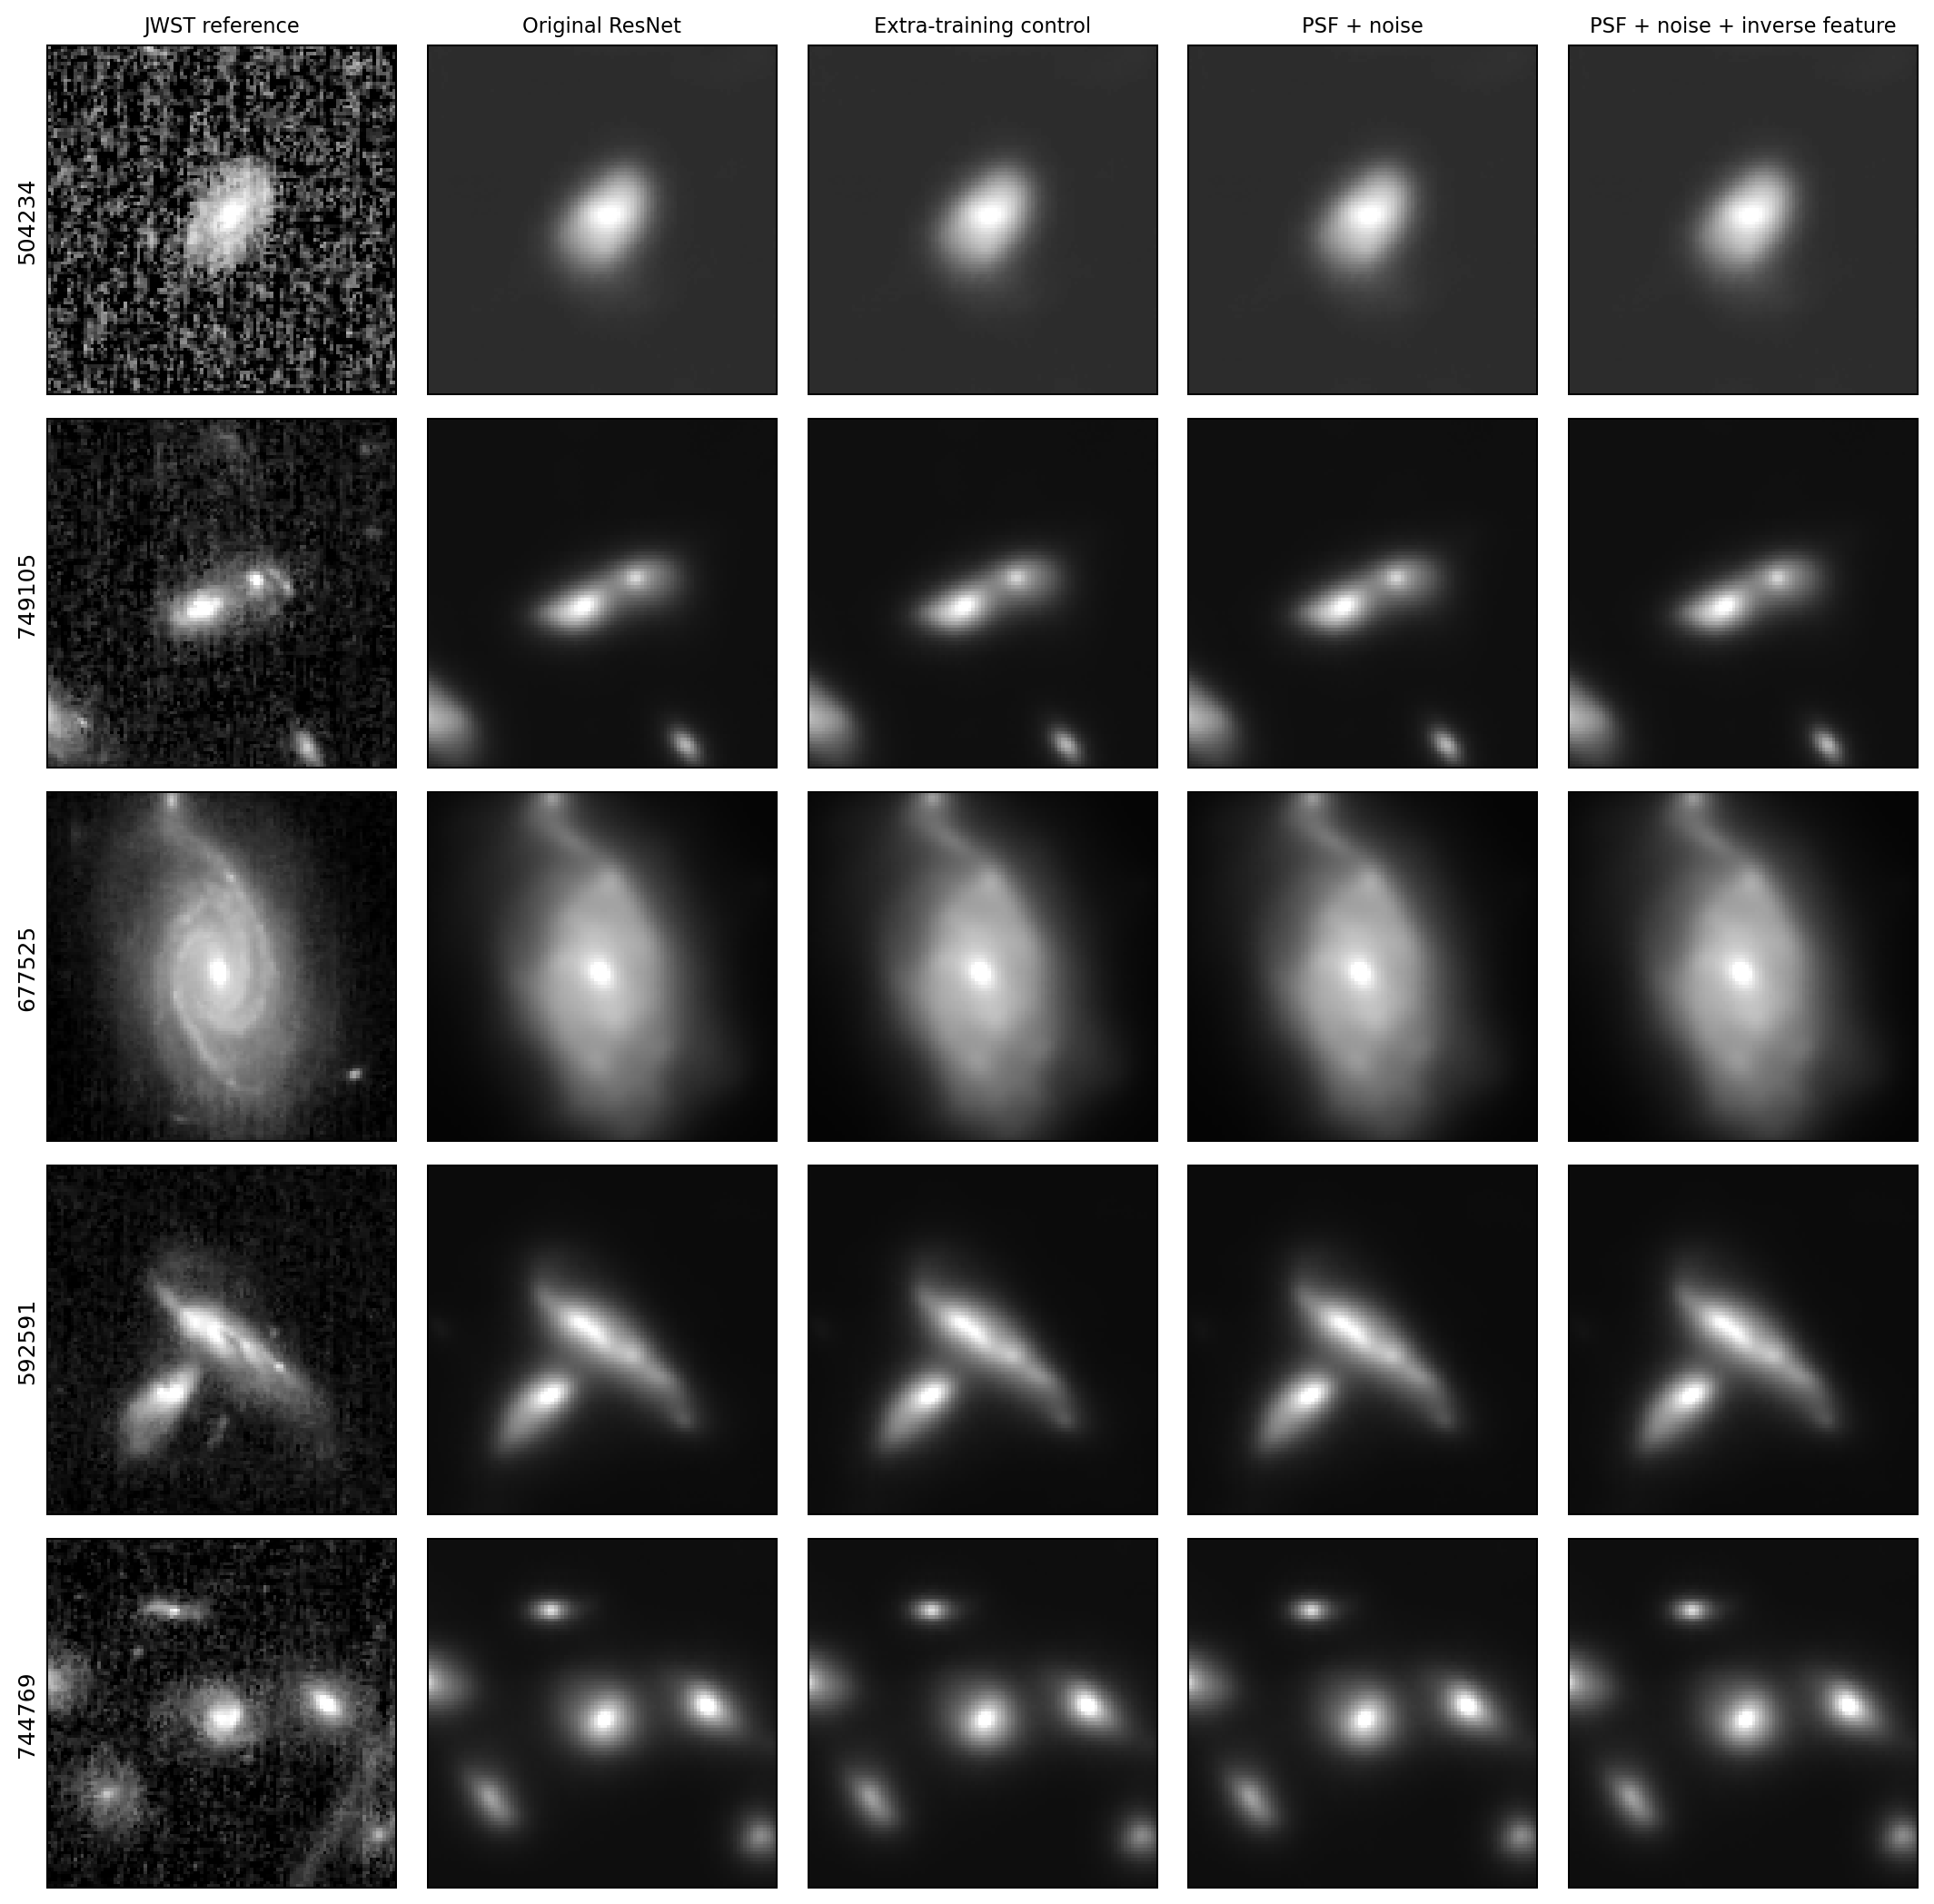

### Fixed residuals

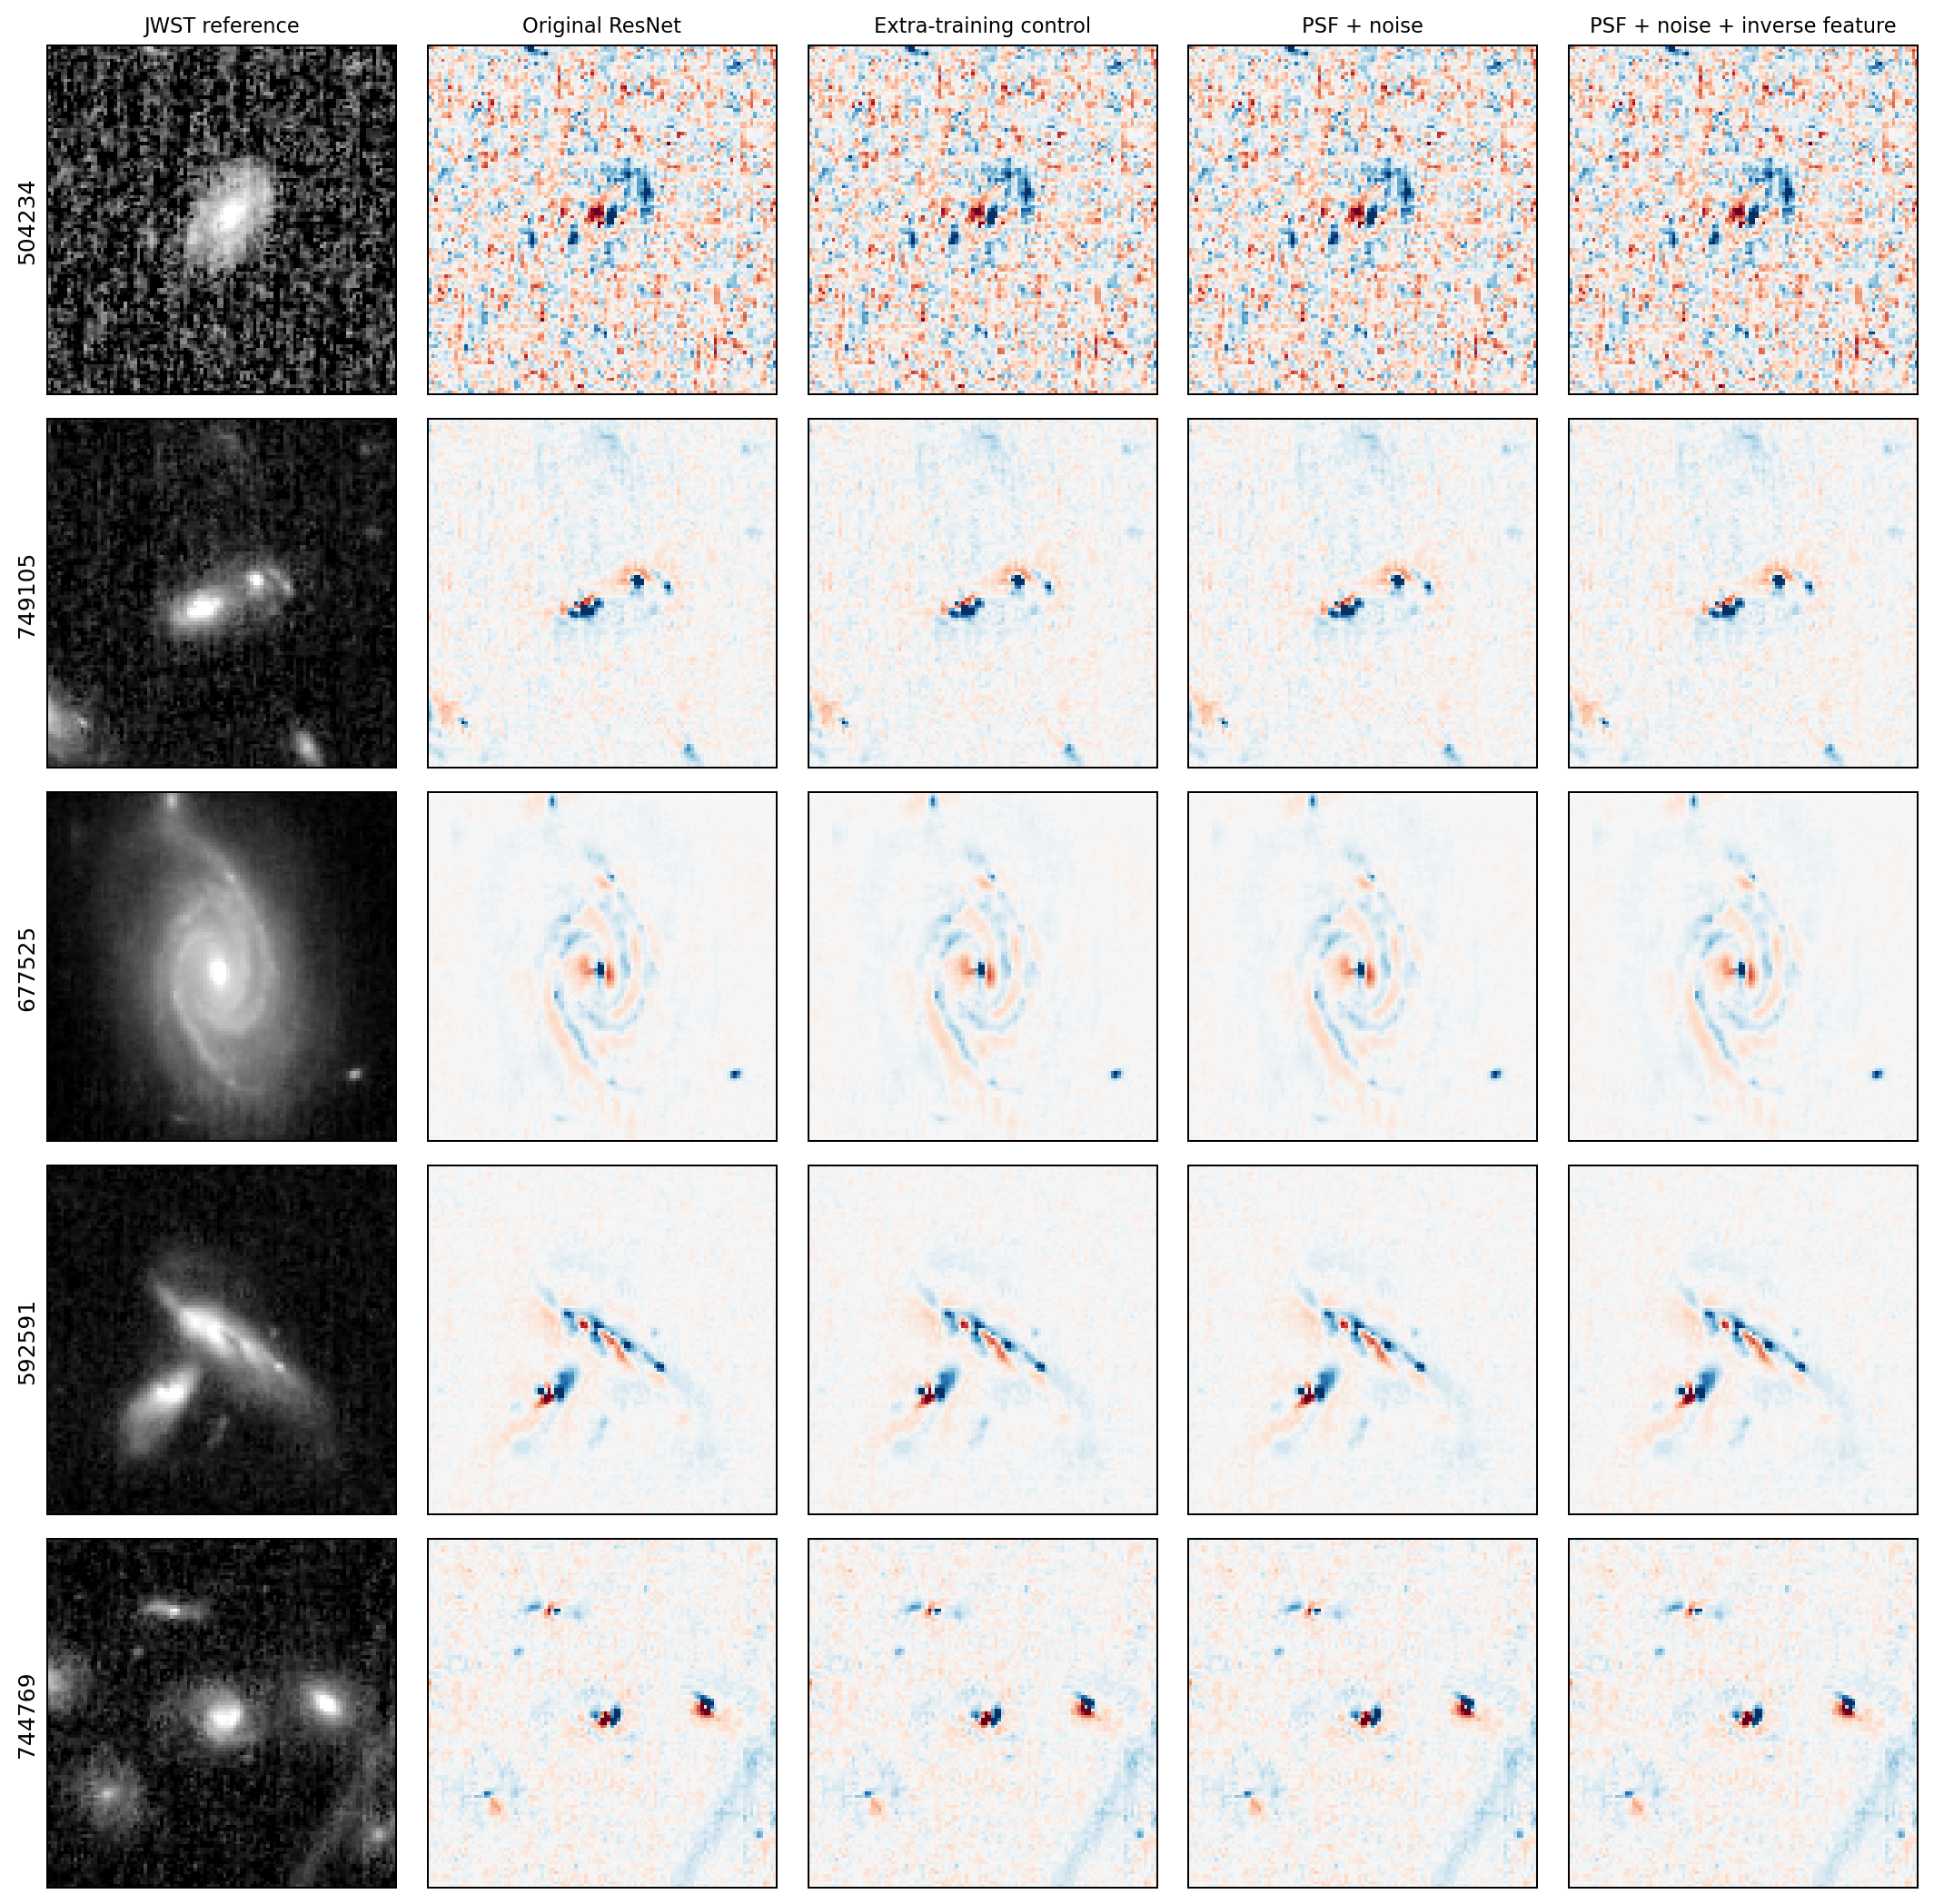

Full paired differences, failure counts, S/N-bin and PSF-stack diagnostics are in `runs/psf-redesign-comparison-v01/comparison.json`. Validation selection and one parent seed limit the interpretation.

In [4]:
if ready:
    for name in ['sharpness_structure', 'learning_curves', 'fixed_images', 'fixed_residuals']:
        display(Markdown('### ' + name.replace('_', ' ').capitalize()))
        display(Image(filename=str(OUT / (name + '.png'))))
    display(Markdown('Full paired differences, failure counts, S/N-bin and PSF-stack diagnostics are in `runs/psf-redesign-comparison-v01/comparison.json`. Validation selection and one parent seed limit the interpretation.'))